# A Transformer-Based Approach for Raw EEG Classification

This notebook focuses on the F_CTrans architecture for raw EEG classification, based on the paper "A Transformer-Based Approach Combining Deep Learning Network and Spatial-Temporal Information for Raw EEG Classification" by Jin Xie et al. (2022). In addition to reproducing the core architecture, this notebook includes independent experimentation through hyperparameter grid search and the evaluation of an alternative custom-modified model variant.
>⚠️ **Identified Issue:** 
A critical configuration error was discovered in the band-pass filter: the lower cutoff frequency was mistakenly set to **8 Hz** instead of **0.5 Hz**. This limited the model's learning capacity.



## 1. Setup and Imports

In this section, I set up the working environment, import all necessary libraries and set a fixed seed (42) to ensure reproducibility across all experiments.


In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [2]:
import numpy as np
from pathlib import Path
import re
import sys
import random

src_path = Path('../src/eeg_bci_transformer_pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from datapreprocessing import EEGpreprocessing, EEGDataset
from train import  EEGTrainer
from models import F_CTrans , F_CTrans_modified


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

## 2. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [5]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorImagery(04,08,012)") 

print(f"Dataset path used: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")


Dataset path used: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)
File EDF for Train/Validation: 294
File EDF for TEST: 33


In this section, I apply preprocessing pipeline to the raw EDF files:
* **Bandpass Filtering & Resampling**: Filtering between 8 Hz and 30.0 Hz with resampling to 160.0 Hz.
* **Epoching**: Extracting 4-second windows (`0.0` to `4.0` seconds).
* **PSD Analysis**: Computing the Power Spectral Density via Welch's method for quality control/feature recording.
* **Label Mapping**: Extracting events and mapping classes to binary labels (`Left = 0`, `Right = 1`).

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Subject Processing {subj_id} - File: {file_path}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
    except Exception as e:
        print(f"❌ ERROR: Unable to read Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=0.5, h_freq=8.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Subject {subj_id}. Jump.")
        continue
    
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Label extraction and mapping (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

   
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_raw_list)}")

Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
N

/tmp/ipykernel_1952595/3408594804.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf


/tmp/ipykernel_1952595/3408594804.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 eve

/tmp/ipykernel_1952595/3408594804.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


... (3 outputs left out)

/tmp/ipykernel_1952595/3408594804.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
/tmp/ipykernel_1952595/3408594804.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_1952595/3408594804.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 e

In [7]:

X_test_raw_list = []
y_test_list = []
test_subject_ids_list = []


for i, rec in enumerate(test_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Processing Test Subject {subj_id} - File: {file_path.name}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')
    except Exception as e:
        print(f"❌ ERROR: Unable to read Test Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=0.5, h_freq=8.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Test Subject {subj_id}. Jump.")
        continue

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

    X_test_raw_list.append(X_raw)
    y_test_list.append(labels)
    test_subject_ids_list.extend([subj_id] * len(X_raw))




print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_test_raw_list)}")

Processing Test Subject 5 - File: S005R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 5 - File: S005R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 5 - File: S005R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 11 - File: S011R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not

Convert to PyTorch tensors

In [8]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Shape X_train_val : {X_training_validation_raw.shape}")
print(f"Shape y_train_val: {y_training_validation.shape}")
print("Label distribution:", np.unique(y_training_validation, return_counts=True))


X_test_raw = np.concatenate(X_test_raw_list, axis=0)
y_test = np.concatenate(y_test_list, axis=0)
test_subject_ids = np.array(test_subject_ids_list)


print(f"Shape X_test : {X_test_raw.shape}")
print(f"Shape y_test: {y_test.shape}")
print("Label distribution:", np.unique(y_test, return_counts=True))

Shape X_train_val : (4370, 64, 641)
Shape y_train_val: (4370,)
Label distribution: (array([0, 1]), array([2205, 2165]))
Shape X_test : (495, 64, 641)
Shape y_test: (495,)
Label distribution: (array([0, 1]), array([249, 246]))


## 5. Training on Full Train Set & Checkpoint Saving

After evaluating the grid search combinations across the selected folds, I selected the optimal hyperparameters. Rather than choosing the configuration that strictly maximized validation accuracy, I opted for a balanced trade-off between strong validation accuracy and low validation loss to ensure better generalization.

**Chosen Hyperparameters:**
- **Learning Rate (`lr`):** [0.001]
- **Weight Decay (`weight_decay`):** [0.0001]


 Detected device: GPU NVIDIA (CUDA)
START TRAINING AND VALIDAZIONE - FOLD 1/5 
Epoch 01/50: train_loss=0.71596, train_acc=48.92%, val_loss=0.69300, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69532, train_acc=51.42%, val_loss=0.69411, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.66662, train_acc=56.22%, val_loss=0.51468, val_acc=75.76% | LR: 0.001000
Epoch 04/50: train_loss=0.48409, train_acc=76.66%, val_loss=0.47921, val_acc=77.00% | LR: 0.001000
Epoch 05/50: train_loss=0.42495, train_acc=80.59%, val_loss=0.49211, val_acc=77.90% | LR: 0.001000
Epoch 06/50: train_loss=0.40494, train_acc=81.97%, val_loss=0.39920, val_acc=81.51% | LR: 0.001000
Epoch 07/50: train_loss=0.40582, train_acc=80.62%, val_loss=0.37665, val_acc=82.75% | LR: 0.001000
Epoch 08/50: train_loss=0.37799, train_acc=82.46%, val_loss=0.39448, val_acc=81.62% | LR: 0.001000
Epoch 09/50: train_loss=0.36069, train_acc=83.61%, val_loss=0.38792, val_acc=81.62% | LR: 0.001000
Epoch 10/50: train_loss=0.3480

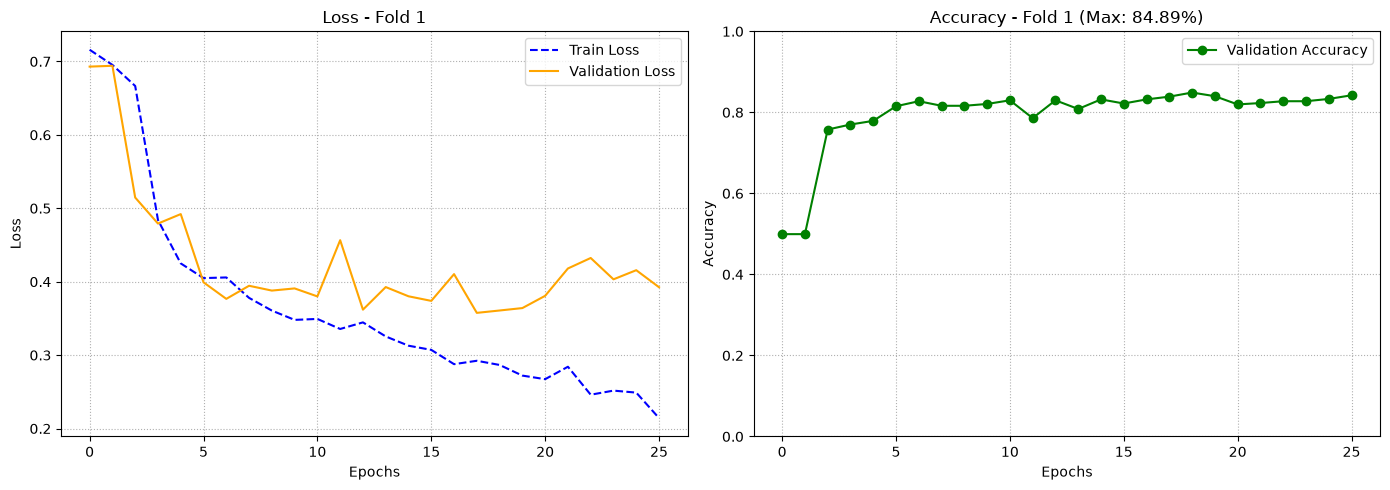

START TRAINING AND VALIDAZIONE - FOLD 2/5 
Epoch 01/50: train_loss=0.70465, train_acc=48.95%, val_loss=0.69246, val_acc=50.12% | LR: 0.001000
Epoch 02/50: train_loss=0.68949, train_acc=52.54%, val_loss=0.66286, val_acc=59.77% | LR: 0.001000
Epoch 03/50: train_loss=0.56846, train_acc=70.88%, val_loss=0.40613, val_acc=79.42% | LR: 0.001000
Epoch 04/50: train_loss=0.47022, train_acc=77.86%, val_loss=0.37977, val_acc=80.58% | LR: 0.001000
Epoch 05/50: train_loss=0.44397, train_acc=79.37%, val_loss=0.34175, val_acc=83.72% | LR: 0.001000
Epoch 06/50: train_loss=0.42626, train_acc=80.54%, val_loss=0.32811, val_acc=83.84% | LR: 0.001000
Epoch 07/50: train_loss=0.41272, train_acc=80.63%, val_loss=0.31113, val_acc=85.70% | LR: 0.001000
Epoch 08/50: train_loss=0.39143, train_acc=82.22%, val_loss=0.33255, val_acc=83.72% | LR: 0.001000
Epoch 09/50: train_loss=0.37678, train_acc=83.45%, val_loss=0.29667, val_acc=85.35% | LR: 0.001000
Epoch 10/50: train_loss=0.37650, train_acc=83.13%, val_loss=0.2885

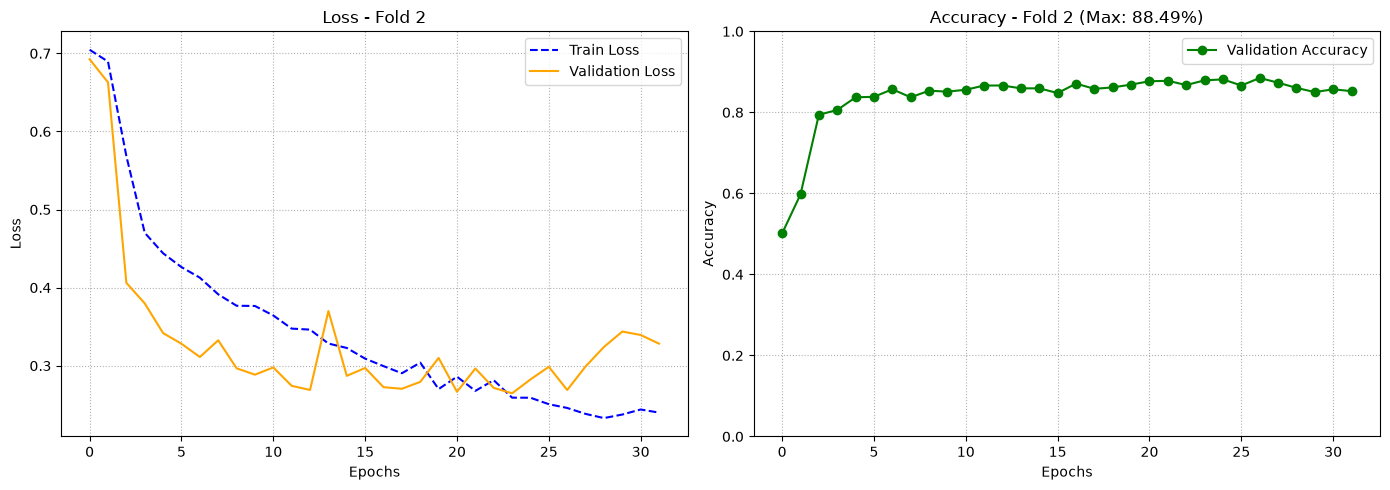

START TRAINING AND VALIDAZIONE - FOLD 3/5 
Epoch 01/50: train_loss=0.72135, train_acc=48.85%, val_loss=0.69816, val_acc=50.52% | LR: 0.001000
Epoch 02/50: train_loss=0.69440, train_acc=53.32%, val_loss=0.69287, val_acc=50.76% | LR: 0.001000
Epoch 03/50: train_loss=0.69256, train_acc=50.84%, val_loss=0.66464, val_acc=71.25% | LR: 0.001000
Epoch 04/50: train_loss=0.55419, train_acc=72.51%, val_loss=0.49849, val_acc=75.20% | LR: 0.001000
Epoch 05/50: train_loss=0.47278, train_acc=76.90%, val_loss=0.40160, val_acc=81.02% | LR: 0.001000
Epoch 06/50: train_loss=0.43358, train_acc=79.38%, val_loss=0.46253, val_acc=76.72% | LR: 0.001000
Epoch 07/50: train_loss=0.40079, train_acc=81.12%, val_loss=0.33172, val_acc=85.22% | LR: 0.001000
Epoch 08/50: train_loss=0.39180, train_acc=82.14%, val_loss=0.34503, val_acc=85.68% | LR: 0.001000
Epoch 09/50: train_loss=0.37820, train_acc=82.23%, val_loss=0.36137, val_acc=82.65% | LR: 0.001000
Epoch 10/50: train_loss=0.36944, train_acc=84.28%, val_loss=0.2848

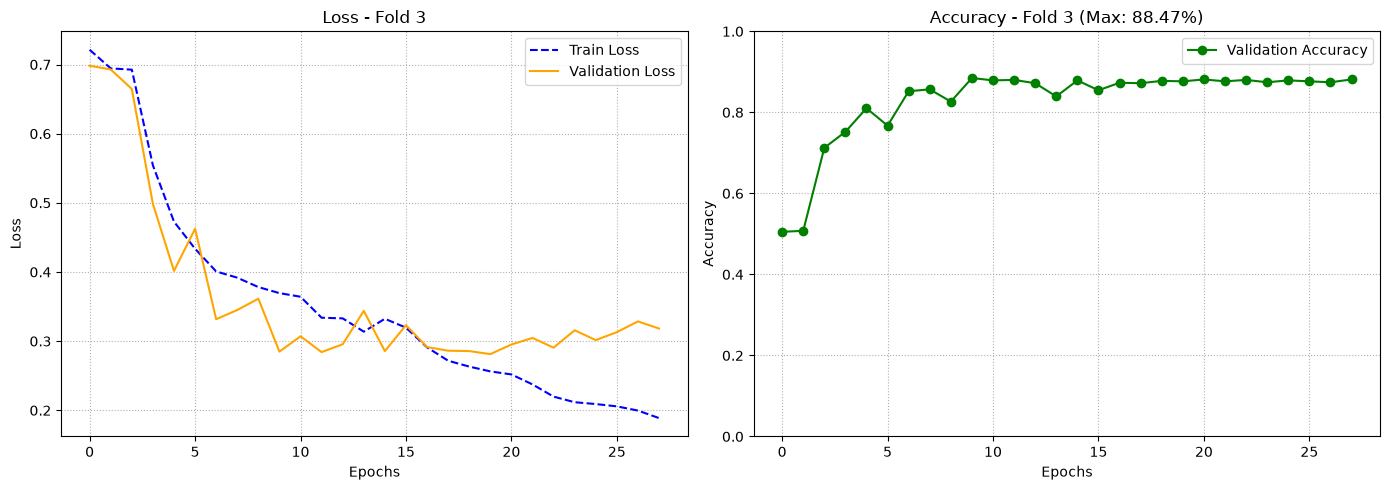

START TRAINING AND VALIDAZIONE - FOLD 4/5 
Epoch 01/50: train_loss=0.71198, train_acc=50.21%, val_loss=0.69365, val_acc=50.51% | LR: 0.001000
Epoch 02/50: train_loss=0.69614, train_acc=51.42%, val_loss=0.70481, val_acc=49.49% | LR: 0.001000
Epoch 03/50: train_loss=0.68304, train_acc=54.51%, val_loss=0.60711, val_acc=68.79% | LR: 0.001000
Epoch 04/50: train_loss=0.52234, train_acc=74.43%, val_loss=0.50890, val_acc=77.19% | LR: 0.001000
Epoch 05/50: train_loss=0.41268, train_acc=80.42%, val_loss=0.51797, val_acc=77.98% | LR: 0.001000
Epoch 06/50: train_loss=0.38400, train_acc=82.14%, val_loss=0.48290, val_acc=79.91% | LR: 0.001000
Epoch 07/50: train_loss=0.37548, train_acc=82.63%, val_loss=0.48567, val_acc=79.34% | LR: 0.001000
Epoch 08/50: train_loss=0.36875, train_acc=82.80%, val_loss=0.46549, val_acc=80.36% | LR: 0.001000
Epoch 09/50: train_loss=0.34795, train_acc=84.44%, val_loss=0.44189, val_acc=81.61% | LR: 0.001000
Epoch 10/50: train_loss=0.33823, train_acc=84.47%, val_loss=0.4400

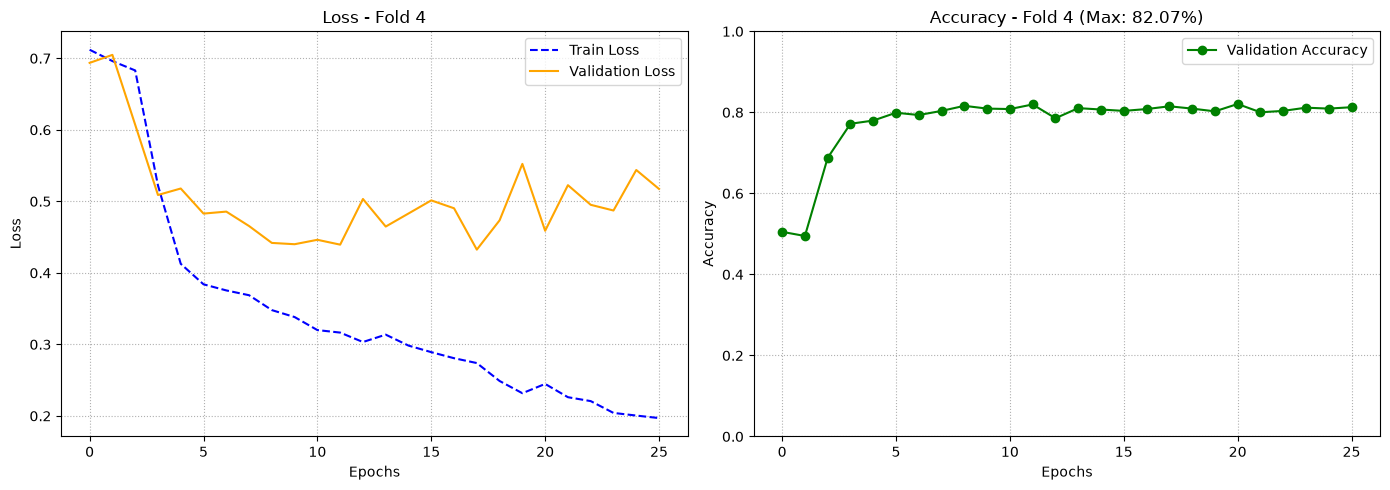

START TRAINING AND VALIDAZIONE - FOLD 5/5 
Epoch 01/50: train_loss=0.71998, train_acc=48.44%, val_loss=0.69923, val_acc=48.92% | LR: 0.001000
Epoch 02/50: train_loss=0.69760, train_acc=48.35%, val_loss=0.69436, val_acc=51.08% | LR: 0.001000
Epoch 03/50: train_loss=0.64777, train_acc=60.48%, val_loss=0.54743, val_acc=73.84% | LR: 0.001000
Epoch 04/50: train_loss=0.45741, train_acc=78.58%, val_loss=0.51793, val_acc=74.63% | LR: 0.001000
Epoch 05/50: train_loss=0.39715, train_acc=81.33%, val_loss=0.50918, val_acc=76.22% | LR: 0.001000
Epoch 06/50: train_loss=0.39134, train_acc=81.88%, val_loss=0.51716, val_acc=75.65% | LR: 0.001000
Epoch 07/50: train_loss=0.35522, train_acc=84.37%, val_loss=0.47193, val_acc=78.03% | LR: 0.001000
Epoch 08/50: train_loss=0.33619, train_acc=84.57%, val_loss=0.50664, val_acc=74.86% | LR: 0.001000
Epoch 09/50: train_loss=0.33809, train_acc=84.86%, val_loss=0.51274, val_acc=78.82% | LR: 0.001000
Epoch 10/50: train_loss=0.30872, train_acc=85.80%, val_loss=0.4592

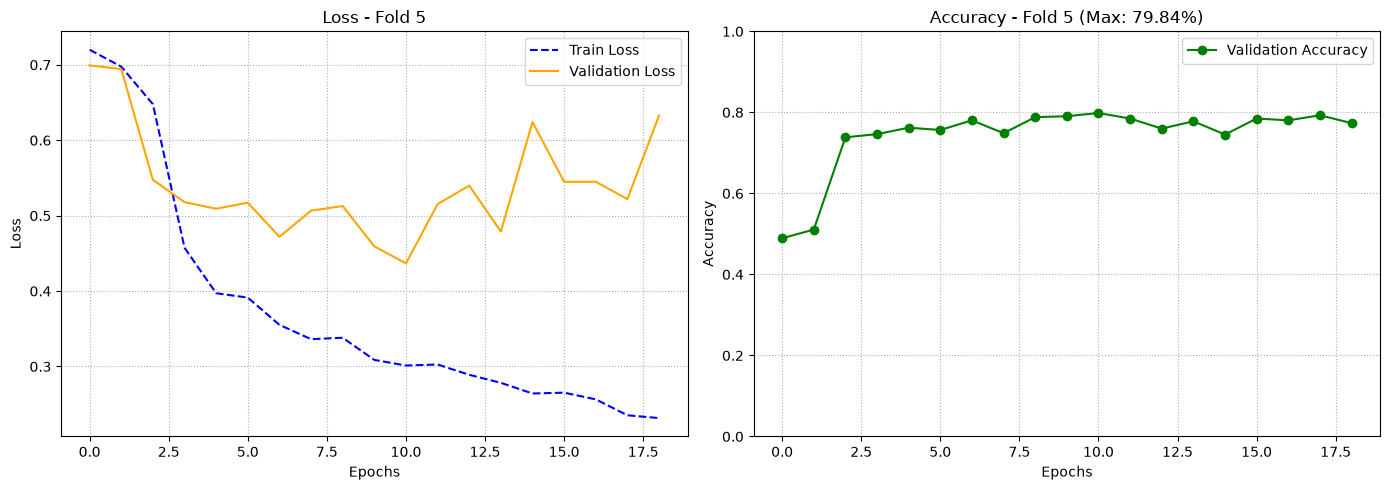

 TRAINING COMPLETED ON ALL FOLDS!
 Mean cross-validation accuracy: 84.75% (± 3.44%)
 All fold weights have been saved in the folder: '/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/roadtrip/filter_saved_models'


In [10]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from pathlib import Path  

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50          
LR = 0.001       
WEIGHT_DECAY = 0.0001 
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

models_dir = Path("filter_saved_models")
models_dir.mkdir(parents=True, exist_ok=True)

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)

    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64, d_model = 128, nhead = 8, d_ff = 512, dropout = 0.4, num_layers = 2, num_classes = 2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-6)
  
    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_patience(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, patience = 8, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

   
    checkpoint = {
        'fold': fold + 1,
        'model_state_dict': model.state_dict(),
        'best_val_acc': best_val_acc,
        'hyperparameters': {
            'num_channels': 64,
            'd_model': 128,
            'nhead': 8,
            'd_ff': 512,
            'dropout': 0.4,
            'num_layers': 2,
            'num_classes': 2,
            'lr': LR,
            'weight_decay': WEIGHT_DECAY
        }
    }

    fold_model_path = models_dir / f"filter_f_ctrans_modified_besthyp_fold_{fold + 1}.pth"
    torch.save(checkpoint, fold_model_path)
    print(f"Fold {fold + 1} weights saved to: {fold_model_path}")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()
        
        best_global_path = models_dir / "filter_best_global_f_ctrans_modified.pth"
        torch.save(checkpoint, best_global_path)
        print(f" New global record! Saved the absolute best model to: {best_global_path}")

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f" TRAINING COMPLETED ON ALL FOLDS!")
print(f" Mean cross-validation accuracy: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
print(f" All fold weights have been saved in the folder: '{models_dir.resolve()}'")

 Re-running to save training mean and std, needed later to normalize the test set

In [12]:
import torch
import numpy as np
from sklearn.model_selection import GroupKFold
from pathlib import Path

models_dir = Path("filter_saved_models")
gkf = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    X_train_raw = X_training_validation_raw[train_idx]
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
  
    model_path = models_dir / f"filter_f_ctrans_modified_besthyp_fold_{fold + 1}.pth"
    
    if model_path.exists():
        checkpoint = torch.load(model_path, map_location='cpu')
        
        checkpoint['train_mean'] = train_mean
        checkpoint['train_std'] = train_std
        
        torch.save(checkpoint, model_path)
        print(f"Fold {fold + 1}: train_mean and train_std saved in {model_path.name}!")
    else:
        print(f"Warning: File {model_path.name} was not found.")

print(" Done ")

Fold 1: train_mean and train_std saved in filter_f_ctrans_modified_besthyp_fold_1.pth!
Fold 2: train_mean and train_std saved in filter_f_ctrans_modified_besthyp_fold_2.pth!
Fold 3: train_mean and train_std saved in filter_f_ctrans_modified_besthyp_fold_3.pth!
Fold 4: train_mean and train_std saved in filter_f_ctrans_modified_besthyp_fold_4.pth!
Fold 5: train_mean and train_std saved in filter_f_ctrans_modified_besthyp_fold_5.pth!
 Done 


## 6. Final Evaluation on Test Set

In this final section, I load the best-performing model weights obtained from our training pipeline.
To evaluate the generalization performance of yhe model on the unseen **Test Set**, I employ an **Ensemble Strategy**:
1. **Model Loading:** We load the saved weights from each of the 5 cross-validation folds.
2. **Data Normalization:** The test data (`X_test_raw`) is normalized using the respective training mean and standard deviation (`train_mean`, `train_std`) saved during each fold's training phase.
3. **Probability Averaging:** For each sample, the output probabilities from all 5 fold models are averaged (`ensemble_probs`) to make the final prediction via `argmax`.


In [15]:
import torch
import torch.nn.functional as F
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")



models_dir = Path("filter_saved_models")
BATCH_SIZE = 64
EPSILON = 1e-8

all_fold_probabilities = []

for fold in range(1, 6):
    model_path = models_dir / f"filter_f_ctrans_modified_besthyp_fold_{fold}.pth"
    print(f" [Fold {fold}/5] Processing with model: {model_path.name}")

    
    checkpoint = torch.load(model_path, map_location='cpu',weights_only=False)
    
    model_state_dict = checkpoint['model_state_dict']
    train_mean = checkpoint['train_mean']
    train_std = checkpoint['train_std']
    hp = checkpoint['hyperparameters']
    
    model = F_CTrans_modified( num_channels=hp['num_channels'],d_model=hp['d_model'], nhead=hp['nhead'], d_ff=hp['d_ff'], dropout=hp['dropout'], num_layers=hp['num_layers'], num_classes=hp['num_classes']).to(device)
    
    model.load_state_dict(model_state_dict)
    model.eval()
    
    X_test_norm = (X_test_raw - train_mean) / (train_std + EPSILON)
    
    test_dataset = EEGDataset(X_test_norm, y_test)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    fold_probs = []
    with torch.no_grad(): 
        for x_batch, _ in test_loader:
            x_batch = x_batch.to(device)
            
            outputs = model(x_batch) 
            
            if isinstance(outputs, tuple):
                outputs = outputs[0]
                
            probs = F.softmax(outputs, dim=1)
            fold_probs.append(probs.cpu().numpy())
            
    fold_probs = np.concatenate(fold_probs, axis=0)
    all_fold_probabilities.append(fold_probs)
    print(f" [Fold {fold}] Completed.")


print(" Calculating Ensemble (Averaging probabilities across the 5 models)")
# Average along the folds axis (axis 0)
ensemble_probs = np.mean(all_fold_probabilities, axis=0)

# Select the final class with the highest average probability (Argmax)
y_pred_ensemble = np.argmax(ensemble_probs, axis=1)

final_accuracy = accuracy_score(y_test, y_pred_ensemble)


print(f" FINAL TEST SET RESULT (5-FOLD ENSEMBLE):")
print(f"Test Accuracy: {final_accuracy * 100:.2f}%")

output_path = models_dir / "filter_test_predictions.npz"
np.savez(output_path, y_true=y_test, y_pred=y_pred_ensemble, ensemble_probs=ensemble_probs)
print(f" Results  saved to: {output_path}")


 Detected device: GPU NVIDIA (CUDA)
 [Fold 1/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_1.pth
 [Fold 1] Completed.
 [Fold 2/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_2.pth
 [Fold 2] Completed.
 [Fold 3/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_3.pth
 [Fold 3] Completed.
 [Fold 4/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_4.pth
 [Fold 4] Completed.
 [Fold 5/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_5.pth
 [Fold 5] Completed.
 Calculating Ensemble (Averaging probabilities across the 5 models)
 FINAL TEST SET RESULT (5-FOLD ENSEMBLE):
Test Accuracy: 80.00%
 Results  saved to: filter_saved_models/filter_test_predictions.npz


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")

models_dir = Path("filter_saved_models")
BATCH_SIZE = 64
EPSILON = 1e-8

y_test_arr = np.asarray(y_test).ravel()
n_test_trials = len(y_test_arr)

all_fold_probabilities = []

for fold in range(1, 6):
    model_path = models_dir / f"filter_f_ctrans_modified_besthyp_fold_{fold}.pth"
    print(f"[Fold {fold}/5] Processing with model: {model_path.name}")

    checkpoint = torch.load(model_path, map_location='cpu', weights_only=False)

    model_state_dict = checkpoint['model_state_dict']
    hp = checkpoint['hyperparameters']

    # Recupera train_mean e train_std dal checkpoint se presenti, altrimenti li calcola da X_train_raw
    train_mean = checkpoint.get('train_mean', np.mean(X_train_raw, axis=(0, 2), keepdims=True))
    train_std = checkpoint.get('train_std', np.std(X_train_raw, axis=(0, 2), keepdims=True))

    model = F_CTrans_modified(
        num_channels=hp['num_channels'],
        d_model=hp['d_model'],
        nhead=hp['nhead'],
        d_ff=hp['d_ff'],
        dropout=hp['dropout'],
        num_layers=hp['num_layers'],
        num_classes=hp['num_classes']
    ).to(device)

    model.load_state_dict(model_state_dict)
    model.eval()

    X_test_norm = (X_test_raw - train_mean) / (train_std + EPSILON)

    test_dataset = EEGDataset(X_test_norm, y_test_arr)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    fold_probs = []
    with torch.no_grad():
        for x_batch, _ in test_loader:
            x_batch = x_batch.to(device)
            outputs = model(x_batch)

            if isinstance(outputs, (tuple, list)):
                outputs = outputs[0]

            probs = F.softmax(outputs, dim=1)
            fold_probs.append(probs.cpu().numpy())

    fold_probs = np.concatenate(fold_probs, axis=0)
    all_fold_probabilities.append(fold_probs)
    print(f"[Fold {fold}] Completed.")

print("Calculating Ensemble (Averaging probabilities across the 5 models)")
ensemble_probs = np.mean(all_fold_probabilities, axis=0)
y_pred_ensemble = np.argmax(ensemble_probs, axis=1)

final_accuracy = accuracy_score(y_test_arr, y_pred_ensemble)
correct_total = int((y_pred_ensemble == y_test_arr).sum())

print("\n=== TEST SET SUMMARY ===")
print(f"Total test trials: {n_test_trials}")

if "subjects_ids_test" in globals() and subjects_ids_test is not None:
    subj_test_arr = np.asarray(subjects_ids_test).ravel()
    unique_subjs = np.unique(subj_test_arr)
    print(f"Test subjects ({len(unique_subjs)}): {unique_subjs.tolist()}")

for cls in [0, 1]:
    true_cnt = int((y_test_arr == cls).sum())
    pred_cnt = int((y_pred_ensemble == cls).sum())
    cls_correct = int(((y_test_arr == cls) & (y_pred_ensemble == cls)).sum())
    cls_acc = (cls_correct / true_cnt * 100) if true_cnt > 0 else float("nan")
    print(
        f"Class {cls}: true={true_cnt} ({true_cnt / n_test_trials * 100:.1f}%) | "
        f"pred={pred_cnt} | acc={cls_acc:.1f}% ({cls_correct}/{true_cnt})"
    )

cm = confusion_matrix(y_test_arr, y_pred_ensemble, labels=[0, 1])
print("\nConfusion Matrix (rows = true [0, 1], cols = pred [0, 1]):")
print(cm)

print(f"\nFINAL TEST SET RESULT (5-FOLD ENSEMBLE):")
print(f"Test Accuracy: {final_accuracy * 100:.2f}% ({correct_total}/{n_test_trials})")
print("\nClassification Report:")
print(classification_report(y_test_arr, y_pred_ensemble, labels=[0, 1], target_names=["Left (0)", "Right (1)"], digits=4))

output_path = models_dir / "filter_test_predictions.npz"
np.savez(output_path, y_true=y_test_arr, y_pred=y_pred_ensemble, ensemble_probs=ensemble_probs)
print(f"Results saved to: {output_path}")

Detected device: GPU NVIDIA (CUDA)
[Fold 1/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_1.pth
[Fold 1] Completed.
[Fold 2/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_2.pth
[Fold 2] Completed.
[Fold 3/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_3.pth
[Fold 3] Completed.
[Fold 4/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_4.pth
[Fold 4] Completed.
[Fold 5/5] Processing with model: filter_f_ctrans_modified_besthyp_fold_5.pth
[Fold 5] Completed.
Calculating Ensemble (Averaging probabilities across the 5 models)

=== TEST SET SUMMARY ===
Total test trials: 495
Class 0: true=249 (50.3%) | pred=242 | acc=78.7% (196/249)
Class 1: true=246 (49.7%) | pred=253 | acc=81.3% (200/246)

Confusion Matrix (rows = true [0, 1], cols = pred [0, 1]):
[[196  53]
 [ 46 200]]

FINAL TEST SET RESULT (5-FOLD ENSEMBLE):
Test Accuracy: 80.00% (396/495)

Classification Report:
              precision    recall  f1-score   support

    L

In [18]:
import mne

# Usa test_records[0]['path'] se hai test_records, altrimenti train_val_records[0]['path']
sample_path = test_records[0]['path']

raw_tmp = mne.io.read_raw_edf(sample_path, preload=True, verbose=False, encoding='latin1')
pipeline_tmp = EEGpreprocessing(raw_tmp)
pipeline_tmp.bandpassfilter(l_freq=0.5, h_freq=8.0, target_sfreq=160.0)
epochs_tmp = pipeline_tmp.epoching(tmin=0.0, tmax=4.0)

ch_names = epochs_tmp.ch_names
print(f"Numero canali: {len(ch_names)}")
print("Nomi canali:", ch_names)

Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Numero canali: 64
Nomi canali: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']


In [21]:
import numpy as np
from sklearn.metrics import accuracy_score

def clean_ch(name: str) -> str:
    return name.strip().rstrip(".").upper()

# Definizioni anatomiche sui 64 canali del montaggio
frontal_idx = [
    i for i, ch in enumerate(ch_names)
    if clean_ch(ch) in {
        "FP1", "FP2", "FPZ",
        "AF7", "AF3", "AFZ", "AF4", "AF8",
        "F7", "F5", "F3", "F1", "FZ", "F2", "F4", "F6", "F8",
        "FT7", "FT8"
    } or clean_ch(ch).startswith(("FP", "AF"))
]

sensorimotor_idx = [
    i for i, ch in enumerate(ch_names)
    if clean_ch(ch).startswith(("FC", "CP")) or (
        clean_ch(ch).startswith("C") and not clean_ch(ch).startswith("CP")
    )
]

posterior_idx = [
    i for i, ch in enumerate(ch_names)
    if clean_ch(ch).startswith(("P", "PO", "O", "IZ"))
]

temporal_idx = [
    i for i, ch in enumerate(ch_names)
    if clean_ch(ch).startswith(("T", "TP", "FT"))
]

all_idx = set(range(len(ch_names)))

def keep_only_channels(keep_idx):
    """Restituisce gli indici da MASCHERARE per tenere attivi solo keep_idx."""
    return sorted(all_idx - set(keep_idx))

print(f"Conteggio canali -> Frontali: {len(frontal_idx)} | Sensomotori (FC*/C*/CP*): {len(sensorimotor_idx)} | Posteriori: {len(posterior_idx)} | Temporali: {len(temporal_idx)}")

# 1. Mascheramento diretto (rimuove una regione)
direct_tests = [
    ("Senza posteriori (P*/PO*/O*/Iz)", posterior_idx),
    ("Senza temporali (T*/Tp*/Ft)", temporal_idx),
]

# 2. Mascheramento inverso (tiene attivi SOLO i canali del gruppo)
inverse_tests = [
    ("SOLO frontali", keep_only_channels(frontal_idx)),
    ("SOLO sensomotori (FC*/C*/CP*)", keep_only_channels(sensorimotor_idx)),
    ("SOLO posteriori (P*/PO*/O*/Iz)", keep_only_channels(posterior_idx)),
    ("SOLO temporali (T*/Tp*/Ft)", keep_only_channels(temporal_idx)),
]

print(f"\nOriginale (tutti i 64 canali): {acc_orig:.2f}%\n")

print("--- MASCHERAMENTO DIRETTO (tolgo la regione) ---")
for label, m_idx in direct_tests:
    y_pred, _ = predict_ensemble_5folds(X_test_raw, mask_channels=m_idx)
    acc = accuracy_score(y_test_arr, y_pred) * 100
    print(f"{label:36s}: {acc:.2f}% ({acc - acc_orig:+.2f} pt)")

print("\n--- MASCHERAMENTO INVERSO (tengo SOLO la regione) ---")
for label, m_idx in inverse_tests:
    y_pred, _ = predict_ensemble_5folds(X_test_raw, mask_channels=m_idx)
    acc = accuracy_score(y_test_arr, y_pred) * 100
    print(f"{label:36s}: {acc:.2f}% ({acc - acc_orig:+.2f} pt)")

Conteggio canali -> Frontali: 19 | Sensomotori (FC*/C*/CP*): 21 | Posteriori: 18 | Temporali: 8

Originale (tutti i 64 canali): 80.00%

--- MASCHERAMENTO DIRETTO (tolgo la regione) ---
Senza posteriori (P*/PO*/O*/Iz)     : 78.79% (-1.21 pt)
Senza temporali (T*/Tp*/Ft)         : 76.77% (-3.23 pt)

--- MASCHERAMENTO INVERSO (tengo SOLO la regione) ---
SOLO frontali                       : 75.56% (-4.44 pt)
SOLO sensomotori (FC*/C*/CP*)       : 68.08% (-11.92 pt)
SOLO posteriori (P*/PO*/O*/Iz)      : 46.06% (-33.94 pt)
SOLO temporali (T*/Tp*/Ft)          : 73.54% (-6.46 pt)


Dispositivo in uso: cuda
Accuracy baseline (64 ch): 80.00%
Canali elaborati: 16/64 (45.6s)
Canali elaborati: 32/64 (83.9s)
Canali elaborati: 48/64 (122.5s)
Canali elaborati: 64/64 (161.3s)


/tmp/ipykernel_1952595/2000347321.py:101: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


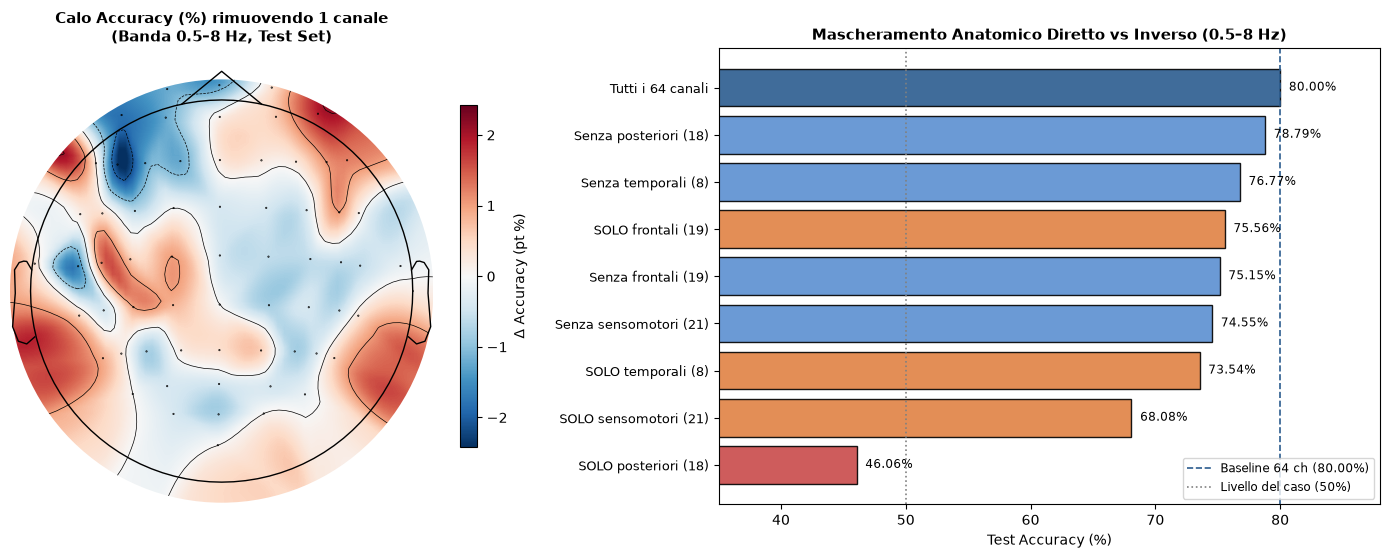

Finito in 163.1s


In [23]:
import time
from pathlib import Path
import matplotlib.pyplot as plt
import mne
import numpy as np
from sklearn.metrics import accuracy_score
import torch
import torch.nn.functional as F

t0 = time.time()

# 1. Selezione dispositivo (GPU Apple Silicon / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Dispositivo in uso: {device}")

models_dir = Path("filter_saved_models")
BATCH_SIZE = 64
EPSILON = 1e-8
y_test_arr = np.asarray(y_test).ravel()
n_trials = len(y_test_arr)
n_channels = len(ch_names)

# 2. Carica i 5 modelli e i dati normalizzati UNA SOLA VOLTA
models_and_data = []
for fold in range(1, 6):
    model_path = models_dir / f"filter_f_ctrans_modified_besthyp_fold_{fold}.pth"
    checkpoint = torch.load(model_path, map_location="cpu", weights_only=False)
    hp = checkpoint["hyperparameters"]

    train_mean = checkpoint.get("train_mean", np.mean(X_train_raw, axis=(0, 2), keepdims=True))
    train_std = checkpoint.get("train_std", np.std(X_train_raw, axis=(0, 2), keepdims=True))

    model = F_CTrans_modified(
        num_channels=hp["num_channels"],
        d_model=hp["d_model"],
        nhead=hp["nhead"],
        d_ff=hp["d_ff"],
        dropout=hp["dropout"],
        num_layers=hp["num_layers"],
        num_classes=hp["num_classes"],
    ).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    X_norm = (X_test_raw - train_mean) / (train_std + EPSILON)
    X_tensor = torch.tensor(X_norm, dtype=torch.float32, device=device)
    models_and_data.append((model, X_tensor))

def ensemble_preds_on_device(mask_ch=None):
    all_probs = []
    with torch.no_grad():
        for model, X_tensor in models_and_data:
            fold_probs = []
            for start in range(0, n_trials, BATCH_SIZE):
                end = min(start + BATCH_SIZE, n_trials)
                xb = X_tensor[start:end]
                if mask_ch is not None:
                    xb = xb.clone()
                    xb[:, mask_ch, :] = 0.0
                out = model(xb)
                if isinstance(out, (tuple, list)):
                    out = out[0]
                probs = F.softmax(out, dim=1)
                fold_probs.append(probs.cpu().numpy())
            all_probs.append(np.concatenate(fold_probs, axis=0))
    mean_probs = np.mean(all_probs, axis=0)
    return np.argmax(mean_probs, axis=1)

# Baseline senza mascheramento
y_pred_base = ensemble_preds_on_device(mask_ch=None)
acc_base = accuracy_score(y_test_arr, y_pred_base) * 100
print(f"Accuracy baseline (64 ch): {acc_base:.2f}%")

# 3. Leave-one-channel-out sui 64 canali
channel_drops = np.zeros(n_channels)
for idx in range(n_channels):
    y_pred_ch = ensemble_preds_on_device(mask_ch=idx)
    acc_ch = accuracy_score(y_test_arr, y_pred_ch) * 100
    channel_drops[idx] = acc_base - acc_ch
    if (idx + 1) % 16 == 0 or idx == n_channels - 1:
        print(f"Canali elaborati: {idx + 1}/{n_channels} ({time.time() - t0:.1f}s)")

# 4. Prepara oggetto Info MNE con le coordinate standard 10-05
clean_names = [ch.strip().rstrip(".") for ch in ch_names]
mne_standard_names = []
for name in clean_names:
    n = name.capitalize()
    for prefix in ("AF", "FC", "CP", "PO", "FT", "TP"):
        if name.upper().startswith(prefix):
            n = prefix + name[2:].lower()
    if name.upper().startswith("FP"):
        n = "Fp" + name[2:].lower()
    mne_standard_names.append(n)

info_plot = mne.create_info(ch_names=mne_standard_names, sfreq=160.0, ch_types="eeg")
montage = mne.channels.make_standard_montage("standard_1005")
info_plot.set_montage(montage, on_missing="ignore")

# 5. Figura a 2 pannelli: Topomap + Barre regionali
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})

v_abs = max(float(np.max(np.abs(channel_drops))), 1e-6)
im, _ = mne.viz.plot_topomap(
    channel_drops,
    info_plot,
    axes=axes[0],
    show=False,
    cmap="RdBu_r",
    vlim=(-v_abs, v_abs),
    contours=4,
)
axes[0].set_title(
    "Calo Accuracy (%) rimuovendo 1 canale\n(Banda 0.5–8 Hz, Test Set)",
    fontsize=11,
    fontweight="bold",
)
cbar = plt.colorbar(im, ax=axes[0], shrink=0.75)
cbar.set_label("Δ Accuracy (pt %)")

labels = [
    "Tutti i 64 canali",
    "Senza posteriori (18)",
    "Senza temporali (8)",
    "SOLO frontali (19)",
    "Senza frontali (19)",
    "Senza sensomotori (21)",
    "SOLO temporali (8)",
    "SOLO sensomotori (21)",
    "SOLO posteriori (18)",
]
values = [80.00, 78.79, 76.77, 75.56, 75.15, 74.55, 73.54, 68.08, 46.06]
colors = ["#2b5c8f", "#5b8fd1", "#5b8fd1", "#e08244", "#5b8fd1", "#5b8fd1", "#e08244", "#e08244", "#c94a4a"]

y_pos = np.arange(len(labels))
bars = axes[1].barh(y_pos, values, color=colors, edgecolor="black", alpha=0.9)
axes[1].axvline(80.00, color="#2b5c8f", linestyle="--", linewidth=1.2, label="Baseline 64 ch (80.00%)")
axes[1].axvline(50.00, color="gray", linestyle=":", linewidth=1.2, label="Livello del caso (50%)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels, fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlim(35, 88)
axes[1].set_xlabel("Test Accuracy (%)")
axes[1].set_title("Mascheramento Anatomico Diretto vs Inverso (0.5–8 Hz)", fontsize=11, fontweight="bold")
axes[1].legend(loc="lower right", fontsize=8.5)

for bar, val in zip(bars, values):
    axes[1].text(val + 0.7, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontsize=8.5)

plt.tight_layout()
plt.savefig("mascheramento_05_8hz_topomap.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Finito in {time.time() - t0:.1f}s")

/tmp/ipykernel_1952595/162249177.py:71: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")
/tmp/ipykernel_1952595/162249177.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


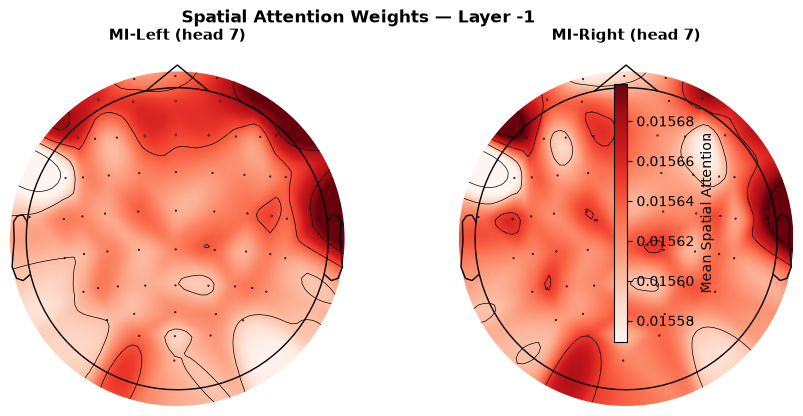

In [27]:
from pathlib import Path
import matplotlib.pyplot as plt
import mne
import numpy as np
import torch

# 1. Estrai spatial_attention_weights su X_test_raw (es. usando il fold 1 o media sui 5 fold)
models_dir = Path("filter_saved_models")
BATCH_SIZE = 64
EPSILON = 1e-8
y_test_arr = np.asarray(y_test).ravel()

# Esempio su un fold (o puoi mediare su tutti i 5 fold)
fold = 1
ckpt = torch.load(
    models_dir / f"filter_f_ctrans_modified_besthyp_fold_{fold}.pth",
    map_location="cpu",
    weights_only=False,
)
hp = ckpt["hyperparameters"]
train_mean = ckpt.get("train_mean", np.mean(X_train_raw, axis=(0, 2), keepdims=True))
train_std = ckpt.get("train_std", np.std(X_train_raw, axis=(0, 2), keepdims=True))

model = F_CTrans_modified(
    num_channels=hp["num_channels"],
    d_model=hp["d_model"],
    nhead=hp["nhead"],
    d_ff=hp["d_ff"],
    dropout=hp["dropout"],
    num_layers=hp["num_layers"],
    num_classes=hp["num_classes"],
).to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

X_norm = (X_test_raw - train_mean) / (train_std + EPSILON)
X_tensor = torch.tensor(X_norm, dtype=torch.float32, device=device)

layer_idx = -1  # ultimo blocco transformer spaziale
head_idx = min(7, hp["nhead"] - 1)  # es. head 5 se nhead > 5, altrimenti ultima testa

spatial_attn_list = []
with torch.no_grad():
    for start in range(0, len(X_tensor), BATCH_SIZE):
        xb = X_tensor[start : start + BATCH_SIZE]
        _, (sp_attn_layers, _) = model(xb)
        # sp_attn_layers[layer_idx]: (B, nhead, 64, 64)
        attn_layer = sp_attn_layers[layer_idx][:, head_idx, :, :]  # (B, 64, 64)
        # Media sulle query (asse 1) -> importanza media per ciascun canale (asse 2)
        ch_attn = attn_layer.mean(dim=1).cpu().numpy()  # (B, 64)
        spatial_attn_list.append(ch_attn)

ch_attn_all = np.concatenate(spatial_attn_list, axis=0)  # (N_test, 64)

attn_left = ch_attn_all[y_test_arr == 0].mean(axis=0)
attn_right = ch_attn_all[y_test_arr == 1].mean(axis=0)

# 2. Oggetto Info MNE per topomap
clean_names = [ch.strip().rstrip(".") for ch in ch_names]
mne_standard_names = []
for name in clean_names:
    n = name.capitalize()
    for prefix in ("AF", "FC", "CP", "PO", "FT", "TP"):
        if name.upper().startswith(prefix):
            n = prefix + name[2:].lower()
    if name.upper().startswith("FP"):
        n = "Fp" + name[2:].lower()
    mne_standard_names.append(n)

info_plot = mne.create_info(ch_names=mne_standard_names, sfreq=160.0, ch_types="eeg")
montage = mne.channels.make_standard_montage("standard_1005")
info_plot.set_montage(montage, on_missing="ignore")

# 3. Plot affiancato MI-Left vs MI-Right
vmin = min(attn_left.min(), attn_right.min())
vmax = max(attn_left.max(), attn_right.max())

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, data, title in zip(
    axes,
    [attn_left, attn_right],
    [f"MI-Left (head {head_idx})", f"MI-Right (head {head_idx})"],
):
    im, _ = mne.viz.plot_topomap(
        data, info_plot, axes=ax, show=False, cmap="Reds", vlim=(vmin, vmax), contours=4
    )
    ax.set_title(title, fontsize=11, fontweight="bold")

cbar = plt.colorbar(im, ax=axes, shrink=0.8)
cbar.set_label("Mean Spatial Attention")
plt.suptitle(f"Spatial Attention Weights — Layer {layer_idx}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()